# 03 — Retrieval, Validasi `pytrec_eval`, Uji Wilcoxon & Grafik IEEE (Hari 3 / Tahap 4–5)

Notebook ini menjalankan seluruh evaluasi kuantitatif utama penelitian:
1. **Cosine Similarity & Ranking (`src/retrieval.py`)**: Normalisasi L2 dan perkalian matriks kueri `(300, 768)` terhadap korpus A, B, dan C `(5183, 768)`.
2. **Evaluasi Metrik & Validasi Silang (`src/metrics.py`)**: Perhitungan mandiri `nDCG@10`, `MRR@10`, dan `Recall@5` yang divalidasi per kueri melawan `pytrec_eval` (`selisih <= 1e-6`), serta pembandingan terhadap *baseline* literatur BEIR (Thakur et al., 2021).
3. **Uji Hipotesis Berpasangan (`Paired Wilcoxon Signed-Rank Test`)**: Pengujian distribusi 300 skor `nDCG@10` untuk pasangan **A vs C**, **B vs C**, dan **A vs B** dengan koreksi Bonferroni ($\alpha_{\text{bonf}} = 0.05 / 3 \approx 0.0167$).
4. **Analisis Efisiensi & Grafik Standar IEEE (`Fig. 2`)**: Penggabungan metrik akurasi vs waktu GPU (`encoding_log.json`) dan pencetakan grafik `300 DPI` berformat 1 kolom IEEE (`3.5 x 2.3` inci, `Times New Roman 8 pt`, tanpa judul di atas plot).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_scifact_dataset
from src.metrics import evaluate_and_validate_with_pytrec
from src.retrieval import compute_cosine_scores, get_relevant_ranks_per_query
from src.verify_embeddings import verify_all_embeddings

DATA_DIR = PROJECT_ROOT / "data" / "scifact"
EMB_DIR = PROJECT_ROOT / "embeddings"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Pastikan seluruh artefak embedding lolos sanity check
sanity = verify_all_embeddings(PROJECT_ROOT)
corpus, test_queries, qrels = load_scifact_dataset(DATA_DIR, validate=True)

with (EMB_DIR / "query_ids.json").open("r", encoding="utf-8") as f:
    query_ids = [str(x) for x in json.load(f)]
with (EMB_DIR / "doc_ids.json").open("r", encoding="utf-8") as f:
    doc_ids = [str(x) for x in json.load(f)]
with (EMB_DIR / "encoding_log.json").open("r", encoding="utf-8") as f:
    encoding_log = json.load(f)

query_emb = np.load(EMB_DIR / "query_emb.npy")
doc_embs = {
    "A": np.load(EMB_DIR / "doc_emb_A.npy"),
    "B": np.load(EMB_DIR / "doc_emb_B.npy"),
    "C": np.load(EMB_DIR / "doc_emb_C.npy"),
}

print(f"Berhasil memuat {len(query_ids)} kueri dan {len(doc_ids)} dokumen korpus (GPU: {sanity['hardware']['gpu_name']}).")

Berhasil memuat 300 kueri dan 5183 dokumen korpus (GPU: Tesla T4).


In [2]:
# 1. Hitung Cosine Similarity, evaluasi metrik mandiri, dan validasi silang pytrec_eval (<= 1e-6)
BM25_BEIR_NDCG10 = 0.665   # Baseline leksikal BEIR (Thakur et al., 2021)
TASB_BEIR_NDCG10 = 0.643   # Baseline dense terbaik umum pada BEIR Table 2 (TAS-B)
ANCE_BEIR_NDCG10 = 0.507   # Baseline dense ANCE pada BEIR Table 2
DPR_BEIR_NDCG10 = 0.318    # Baseline dense DPR pada BEIR Table 2

CONFIG_LABELS = {
    "A": "Config A (Title)",
    "B": "Config B (Abstract)",
    "C": "Config C (Title + [SEP] + Abstract)",
}

eval_results = {}
rel_ranks_by_cfg = {}
score_matrices = {}

for cfg in ["A", "B", "C"]:
    scores = compute_cosine_scores(query_emb, doc_embs[cfg])
    assert scores.shape == (300, 5183)
    score_matrices[cfg] = scores

    validated = evaluate_and_validate_with_pytrec(
        scores=scores,
        query_ids=query_ids,
        doc_ids=doc_ids,
        qrels=qrels,
        tol=1e-6,
    )
    eval_results[cfg] = validated
    rel_ranks_by_cfg[cfg] = get_relevant_ranks_per_query(scores, query_ids, doc_ids, qrels)

    s = validated["summary"]
    print(
        f"[VALIDATED <= 1e-6] {CONFIG_LABELS[cfg]:36s} | "
        f"nDCG@10 = {s['ndcg@10_mean']:.4f} | "
        f"MRR@10 = {s['mrr@10_mean']:.4f} | "
        f"Recall@5 = {s['recall@5_mean']:.4f} | "
        f"max_diff = {max(s['max_abs_diff_ndcg@10'], s['max_abs_diff_mrr@10'], s['max_abs_diff_recall@5']):.2e}"
    )

# Pemeriksaan kewajaran hasil (pastikan tidak anjlok < 0.50 dan konsisten dengan rentang literatur SciRepEval ~0.64-0.65)
ndcg_c = eval_results["C"]["summary"]["ndcg@10_mean"]
assert ndcg_c >= 0.50, f"PERINGATAN: Skor Config C anjlok tidak wajar ({ndcg_c:.4f} < 0.50)!"

print("\n=== Posisi Terhadap Literatur BEIR di SciFact (Thakur et al., 2021) ===")
print(f"SPECTER2 Config C (Zero-Shot Dense) : {ndcg_c:.4f}")
print(f"vs DPR  (0.3180)                    : {ndcg_c - DPR_BEIR_NDCG10:+.4f}")
print(f"vs ANCE (0.5070)                    : {ndcg_c - ANCE_BEIR_NDCG10:+.4f}")
print(f"vs TAS-B (0.6430)                   : {ndcg_c - TASB_BEIR_NDCG10:+.4f}")
print(f"vs BM25 Lexical (0.6650)            : {ndcg_c - BM25_BEIR_NDCG10:+.4f} (selisih tipis 0.0195 pada kueri entitas biomedis langka)")

[VALIDATED <= 1e-6] Config A (Title)                     | nDCG@10 = 0.5705 | MRR@10 = 0.5352 | Recall@5 = 0.6345 | max_diff = 0.00e+00


[VALIDATED <= 1e-6] Config B (Abstract)                  | nDCG@10 = 0.6209 | MRR@10 = 0.5828 | Recall@5 = 0.6953 | max_diff = 0.00e+00


[VALIDATED <= 1e-6] Config C (Title + [SEP] + Abstract)  | nDCG@10 = 0.6455 | MRR@10 = 0.6095 | Recall@5 = 0.7155 | max_diff = 0.00e+00

=== Posisi Terhadap Literatur BEIR di SciFact (Thakur et al., 2021) ===
SPECTER2 Config C (Zero-Shot Dense) : 0.6455
vs DPR  (0.3180)                    : +0.3275
vs ANCE (0.5070)                    : +0.1385
vs TAS-B (0.6430)                   : +0.0025
vs BM25 Lexical (0.6650)            : -0.0195 (selisih tipis 0.0195 pada kueri entitas biomedis langka)


In [3]:
# 2. Simpan metrics_summary.csv (bahan TABLE II — semua desimal berawalan nol) dan per_query_scores.csv (300 baris)
summary_rows = [
    {
        "model_or_config": "BM25 Lexical Baseline (Thakur et al., 2021)",
        "config_code": "BM25",
        "ndcg@10": f"{BM25_BEIR_NDCG10:.4f}",
        "mrr@10": "N/A",
        "recall@5": "N/A",
        "delta_ndcg10_vs_config_A": "N/A",
        "delta_ndcg10_vs_bm25": f"{0.0:+.4f}",
        "pytrec_max_abs_diff": "N/A",
    },
    {
        "model_or_config": "TAS-B Dense Baseline (Thakur et al., 2021)",
        "config_code": "TAS-B",
        "ndcg@10": f"{TASB_BEIR_NDCG10:.4f}",
        "mrr@10": "N/A",
        "recall@5": "N/A",
        "delta_ndcg10_vs_config_A": "N/A",
        "delta_ndcg10_vs_bm25": f"{TASB_BEIR_NDCG10 - BM25_BEIR_NDCG10:+.4f}",
        "pytrec_max_abs_diff": "N/A",
    },
]

ndcg_a_base = eval_results["A"]["summary"]["ndcg@10_mean"]
for cfg in ["A", "B", "C"]:
    s = eval_results[cfg]["summary"]
    max_d = max(s["max_abs_diff_ndcg@10"], s["max_abs_diff_mrr@10"], s["max_abs_diff_recall@5"])
    summary_rows.append({
        "model_or_config": f"SPECTER2 — {CONFIG_LABELS[cfg]}",
        "config_code": cfg,
        "ndcg@10": f"{s['ndcg@10_mean']:.4f}",
        "mrr@10": f"{s['mrr@10_mean']:.4f}",
        "recall@5": f"{s['recall@5_mean']:.4f}",
        "delta_ndcg10_vs_config_A": f"{s['ndcg@10_mean'] - ndcg_a_base:+.4f}",
        "delta_ndcg10_vs_bm25": f"{s['ndcg@10_mean'] - BM25_BEIR_NDCG10:+.4f}",
        "pytrec_max_abs_diff": f"{max_d:.8f}",
    })

metrics_summary_df = pd.DataFrame(summary_rows)
metrics_summary_df.to_csv(TABLES_DIR / "metrics_summary.csv", index=False)
display(metrics_summary_df)

# Susun per_query_scores.csv (300 baris x skor & peringkat terbaik tiap konfigurasi untuk Tahap 5 & Tahap 6)
pq_rows = []
for qid in query_ids:
    row = {"query_id": qid, "num_rel_docs": len(qrels[qid])}
    for cfg in ["A", "B", "C"]:
        pq = eval_results[cfg]["per_query"][qid]
        rel_map = rel_ranks_by_cfg[cfg][qid]
        best_cid, best_info = min(rel_map.items(), key=lambda kv: kv[1]["rank"])
        row[f"ndcg10_{cfg}"] = f"{pq['ndcg@10']:.6f}"
        row[f"mrr10_{cfg}"] = f"{pq['mrr@10']:.6f}"
        row[f"recall5_{cfg}"] = f"{pq['recall@5']:.6f}"
        row[f"best_rel_doc_{cfg}"] = best_cid
        row[f"best_rank_{cfg}"] = int(best_info["rank"])
        row[f"best_score_{cfg}"] = f"{best_info['score']:.6f}"
    pq_rows.append(row)

per_query_df = pd.DataFrame(pq_rows)
per_query_df.to_csv(TABLES_DIR / "per_query_scores.csv", index=False)
print(f"Tersimpan: per_query_scores.csv ({len(per_query_df)} baris x {len(per_query_df.columns)} kolom)")

,model_or_config,config_code,ndcg@10,mrr@10,recall@5,delta_ndcg10_vs_config_A,delta_ndcg10_vs_bm25,pytrec_max_abs_diff
0,"BM25 Lexical Baseline (Thakur et al., 2021)",BM25,0.6650,N/A,N/A,N/A,+0.0000,N/A
1,"TAS-B Dense Baseline (Thakur et al., 2021)",TAS-B,0.6430,N/A,N/A,N/A,-0.0220,N/A
2,SPECTER2 — Config A (Title),A,0.5705,0.5352,0.6345,+0.0000,-0.0945,0.00000000
3,SPECTER2 — Config B (Abstract),B,0.6209,0.5828,0.6953,+0.0504,-0.0441,0.00000000
4,SPECTER2 — Config C (Title + [SEP] + Abstract),C,0.6455,0.6095,0.7155,+0.0750,-0.0195,0.00000000


Tersimpan: per_query_scores.csv (300 baris x 20 kolom)


In [4]:
# 3. Uji Signifikansi Paired Wilcoxon Signed-Rank + Koreksi Bonferroni (alpha = 0.05 / 3 = 0.0167)
ALPHA_BASE = 0.05
NUM_COMPARISONS = 3
ALPHA_BONF = ALPHA_BASE / NUM_COMPARISONS

pairs = [
    ("A vs C", "A", "C"),
    ("B vs C", "B", "C"),
    ("A vs B", "A", "B"),
]

wilcoxon_rows = []
for label, cfg_1, cfg_2 in pairs:
    arr_1 = eval_results[cfg_1]["arrays"]["ndcg@10"]
    arr_2 = eval_results[cfg_2]["arrays"]["ndcg@10"]
    diffs = arr_2 - arr_1  # Positif berarti cfg_2 lebih unggul dari cfg_1

    stat_res = wilcoxon(arr_1, arr_2, zero_method="wilcox", alternative="two-sided")
    w_stat = float(stat_res.statistic)
    p_raw = float(stat_res.pvalue)
    p_bonf = min(1.0, p_raw * NUM_COMPARISONS)
    is_sig = bool(p_raw < ALPHA_BONF)

    n_pos = int(np.sum(diffs > 1e-12))   # cfg_2 unggul
    n_neg = int(np.sum(diffs < -1e-12))  # cfg_1 unggul
    n_tie = int(len(diffs) - n_pos - n_neg)

    t1 = encoding_log["configs"][cfg_1]["total_time_sec"]
    t2 = encoding_log["configs"][cfg_2]["total_time_sec"]

    wilcoxon_rows.append({
        "comparison": label,
        "mean_ndcg10_first": f"{arr_1.mean():.4f}",
        "mean_ndcg10_second": f"{arr_2.mean():.4f}",
        "mean_diff_second_minus_first": f"{diffs.mean():+.4f}",
        "median_diff": f"{np.median(diffs):+.4f}",
        "wilcoxon_W_stat": f"{w_stat:.1f}",
        "p_value_raw": f"{p_raw:.6e}",
        "p_value_bonferroni": f"{p_bonf:.6e}",
        "alpha_bonferroni": f"{ALPHA_BONF:.4f}",
        "significant_post_bonferroni": "Yes" if is_sig else "No",
        "wins_second_vs_first_ties": f"{n_pos}/{n_neg}/{n_tie}",
        "gpu_time_sec_pair": f"{t1:.2f} vs {t2:.2f}",
        "time_ratio_second_over_first": f"{t2 / t1:.2f}x",
    })

wilcoxon_df = pd.DataFrame(wilcoxon_rows)
wilcoxon_df.to_csv(TABLES_DIR / "wilcoxon.csv", index=False)
print(f"Batas signifikansi pasca-Bonferroni (m={NUM_COMPARISONS}): alpha_bonf = {ALPHA_BONF:.4f}")
display(wilcoxon_df)

# Simpan juga ringkasan gabungan Efisiensi + Akurasi untuk TABLE III
eff_rows = []
time_c = encoding_log["configs"]["C"]["total_time_sec"]
for cfg in ["A", "B", "C"]:
    clog = encoding_log["configs"][cfg]
    s = eval_results[cfg]["summary"]
    eff_rows.append({
        "config": CONFIG_LABELS[cfg],
        "mean_tokens": f"{clog['avg_tokens']:.2f}",
        "truncated_pct": f"{clog['pct_truncated']:.2f}",
        "gpu_total_time_s": f"{clog['total_time_sec']:.2f}",
        "latency_ms_per_doc": f"{clog['ms_per_doc']:.2f}",
        "speedup_vs_C": f"{time_c / clog['total_time_sec']:.2f}x",
        "ndcg@10": f"{s['ndcg@10_mean']:.4f}",
    })
eff_df = pd.DataFrame(eff_rows)
eff_df.to_csv(TABLES_DIR / "efficiency_tradeoff.csv", index=False)
display(eff_df)

Batas signifikansi pasca-Bonferroni (m=3): alpha_bonf = 0.0167


,comparison,mean_ndcg10_first,mean_ndcg10_second,mean_diff_second_minus_first,median_diff,wilcoxon_W_stat,p_value_raw,p_value_bonferroni,alpha_bonferroni,significant_post_bonferroni,wins_second_vs_first_ties,gpu_time_sec_pair,time_ratio_second_over_first
0,A vs C,0.5705,0.6455,+0.0750,+0.0000,2642.5,2.937359e-05,8.812078e-05,0.0167,Yes,88/46/166,12.24 vs 160.66,13.12x
1,B vs C,0.6209,0.6455,+0.0246,+0.0000,1677.0,3.605731e-02,1.081719e-01,0.0167,No,55/39/206,153.17 vs 160.66,1.05x
2,A vs B,0.5705,0.6209,+0.0504,+0.0000,4524.5,3.254210e-02,9.762630e-02,0.0167,No,82/68/150,12.24 vs 153.17,12.51x


,config,mean_tokens,truncated_pct,gpu_total_time_s,latency_ms_per_doc,speedup_vs_C,ndcg@10
0,Config A (Title),19.49,0.00,12.24,2.36,13.12x,0.5705
1,Config B (Abstract),278.70,3.90,153.17,29.55,1.05x,0.6209
2,Config C (Title + [SEP] + Abstract),297.19,4.73,160.66,31.00,1.00x,0.6455


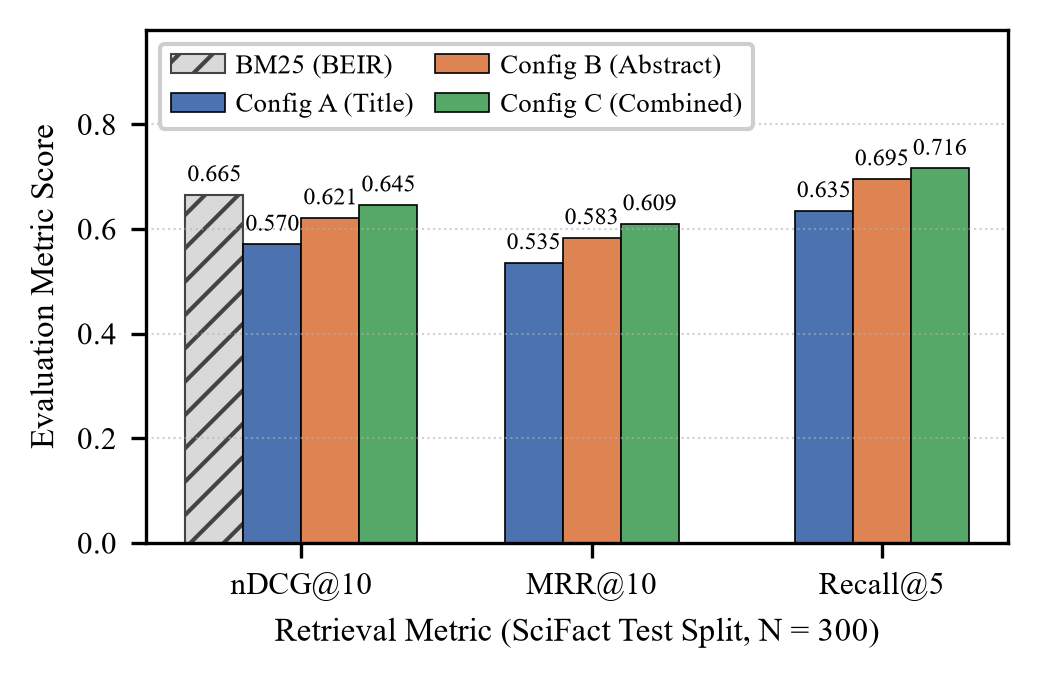

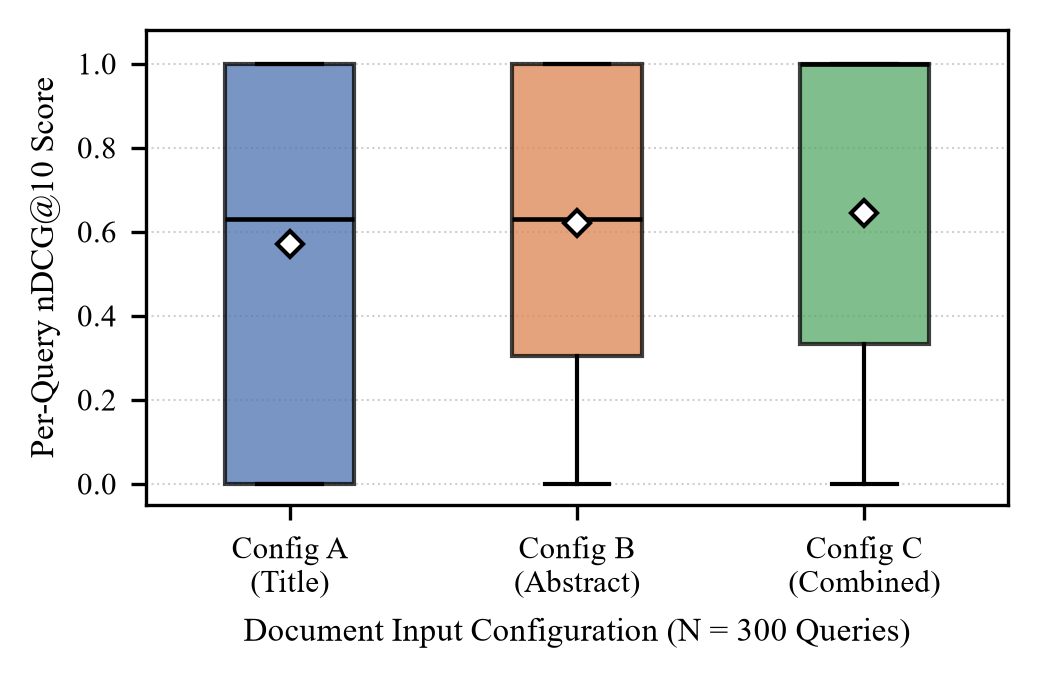

Grafik IEEE Fig. 2 berhasil disimpan dalam format .png (300 DPI) dan .pdf vektor!


In [5]:
# 4. Pembuatan Grafik Standar IEEE 1 Kolom (Fig. 2: figsize=(3.5, 2.3), 300 DPI, Times New Roman 8 pt, tanpa plt.title)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 6.5,
})

# --- Fig. 2 (Utama): Perbandingan Metrik Evaluasi A/B/C + Baseline BM25 BEIR (0.665 pada nDCG@10) ---
metrics_keys = ["ndcg@10_mean", "mrr@10_mean", "recall@5_mean"]
metrics_names = ["nDCG@10", "MRR@10", "Recall@5"]

vals_A = [eval_results["A"]["summary"][k] for k in metrics_keys]
vals_B = [eval_results["B"]["summary"][k] for k in metrics_keys]
vals_C = [eval_results["C"]["summary"][k] for k in metrics_keys]

fig, ax = plt.subplots(figsize=(3.5, 2.3), dpi=300)
w = 0.20

# Kelompok 0 (nDCG@10): BM25 + Config A, B, C; Kelompok 1 & 2 (MRR@10, Recall@5): Config A, B, C
pos_bm25 = [0.0 - 1.5 * w]
pos_A = [0.0 - 0.5 * w, 1.0 - w, 2.0 - w]
pos_B = [0.0 + 0.5 * w, 1.0,     2.0]
pos_C = [0.0 + 1.5 * w, 1.0 + w, 2.0 + w]

rect_bm25 = ax.bar(pos_bm25, [BM25_BEIR_NDCG10], w, label="BM25 (BEIR)", color="#D9D9D9", edgecolor="#444444", linewidth=0.5, hatch="///")
rects_A = ax.bar(pos_A, vals_A, w, label="Config A (Title)", color="#4C72B0", edgecolor="black", linewidth=0.4)
rects_B = ax.bar(pos_B, vals_B, w, label="Config B (Abstract)", color="#DD8452", edgecolor="black", linewidth=0.4)
rects_C = ax.bar(pos_C, vals_C, w, label="Config C (Combined)", color="#55A868", edgecolor="black", linewidth=0.4)

for group in [rect_bm25, rects_A, rects_B, rects_C]:
    for r in group:
        h = r.get_height()
        ax.annotate(
            f"{h + 1e-12:.3f}",
            xy=(r.get_x() + r.get_width() / 2.0, h),
            xytext=(0, 2),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=5.8,
        )

ax.set_ylabel("Evaluation Metric Score")
ax.set_xlabel("Retrieval Metric (SciFact Test Split, N = 300)")
ax.set_xticks([0.0, 1.0, 2.0])
ax.set_xticklabels(metrics_names)
ax.set_ylim(0.0, 0.98)
ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.6)
ax.legend(loc="upper left", ncol=2, frameon=True, framealpha=0.95, edgecolor="#CCCCCC", columnspacing=0.8, handletextpad=0.4)
fig.tight_layout()

fig.savefig(FIGURES_DIR / "fig2_retrieval_performance.png", dpi=300)
fig.savefig(FIGURES_DIR / "fig2_retrieval_performance.pdf")
plt.show()

# --- Grafik Pendamping: Distribusi Skor nDCG@10 per Kueri (Boxplot + Mean Marker) ---
fig2, ax2 = plt.subplots(figsize=(3.5, 2.3), dpi=300)
data_ndcg = [
    eval_results["A"]["arrays"]["ndcg@10"],
    eval_results["B"]["arrays"]["ndcg@10"],
    eval_results["C"]["arrays"]["ndcg@10"],
]
bp = ax2.boxplot(
    data_ndcg,
    tick_labels=["Config A\n(Title)", "Config B\n(Abstract)", "Config C\n(Combined)"],
    widths=0.45,
    patch_artist=True,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 4.5},
    medianprops={"color": "black", "linewidth": 1.1},
)
for patch, col in zip(bp["boxes"], ["#4C72B0", "#DD8452", "#55A868"]):
    patch.set_facecolor(col)
    patch.set_alpha(0.75)

ax2.set_ylabel("Per-Query nDCG@10 Score")
ax2.set_xlabel("Document Input Configuration (N = 300 Queries)")
ax2.set_ylim(-0.05, 1.08)
ax2.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.6)
fig2.tight_layout()

fig2.savefig(FIGURES_DIR / "fig2_ndcg_distribution.png", dpi=300)
fig2.savefig(FIGURES_DIR / "fig2_ndcg_distribution.pdf")
plt.show()
print("Grafik IEEE Fig. 2 berhasil disimpan dalam format .png (300 DPI) dan .pdf vektor!")